# 14. 사고다발지점 연관 도로 특성 분류 (곁다리 분석)

메인 속도 예측 파이프라인(`pipeline/04`~`05`, `models/11`)은 사고다발지역 여부(`accident_hotspot_count`)를 **입력 피처**로만 써왔다(기여도 +0.006~+0.010에 그침). 이 노트북은 라벨과 피처를 뒤집어, 속도 대신 **사고다발지역 여부를 라벨**로 놓고 나머지 도로/지형/위상/시간/기상/속도 피처가 이를 얼마나 설명하는지 본다.

## 데이터
- 라벨 원본: `data/raw/traffic/pedestrian_accident_2019_2024.csv` (TAAS 보행자 사고다발지역, 서울 1,984개 zone, zone당 2019~2024년 보행자사고 7건 이상)
- 이미 `pipeline/04_build_link_dimension.py`가 링크 geometry와 사고다발 폴리곤을 `sjoin(intersects)`해 `seoul_link_dimension.csv`의 `accident_hotspot_count`로 만들어둠(63,548개 링크 중 2,438개=3.84%만 non-zero)
- 이 노트북은 `seoul_link_dimension.csv`(정적, 링크당 1행)와 `seoul_link_speed_fact.csv`(동적, (링크,날짜,시간)당 1행, 15,094,335행)를 `LINK_ID`로 결합해 사용한다 — 속도는 더이상 라벨이 아니라 **피처**로 들어간다(평균속도가 낮거나 변동성이 큰 링크가 사고와 관련있을 가능성이 있으므로).

## 주의
- 양성(사고다발) 비율이 3.84%로 극도로 불균형 → accuracy 대신 PR-AUC/ROC-AUC 사용
- 라벨이 링크당 고정값이므로, 모델이 "새로운 링크"에 일반화되는지를 보려면 같은 링크의 행들이 train/test에 나뉘어지면 안 된다 → `LINK_ID` 기준 그룹 분할(StratifiedGroupKFold) 사용
- `school_zone_count`/`speed_bump_count`는 사고 이후 안전대책으로 설치되었을 수 있어 **역인과관계** 가능성이 있다 — 중요 피처로 나와도 "사고를 유발한다"가 아니라 "동행한다"로 해석
- 이번 노트북은 **모델 학습/검증까지만** 다룬다(심도 해석/SHAP은 다음 단계).

In [1]:
import platform
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "docs" / "figures" / "accident"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DIMENSION_PATH = PROCESSED_DIR / "seoul_link_dimension.csv"   # pipeline/04 산출 (링크당 1행)
FACT_PATH = PROCESSED_DIR / "seoul_link_speed_fact.csv"       # pipeline/05 산출 (링크x날짜x시간)

# 실험용(임시): 생활인구 — 아직 pipeline/04/05나 seoul_link_dimension.csv에는 안 붙임
LINK_SHP = INTERIM_DIR / "seoul_link.shp"
GRID_MATCH_SHP = RAW_DIR / "traffic" / "match" / "match.shp"                        # 250M격자 CELL_ID -> geometry
GRID_POP_DIR = RAW_DIR / "traffic" / "250_LOCAL_RESD_202607"                        # 250m 격자 생활인구(일별)
DONG_POP_DIR = RAW_DIR / "traffic" / "250_LOCAL_RESD_ADMDONG_202607"                # 행정동 생활인구(일별)

plt.rcParams["font.family"] = "AppleGothic" if platform.system() == "Darwin" else "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
N_FOLDS = 5
SAMPLE_FRAC = 1.0  # 빠르게 돌려볼 때 0.15 정도로 낮추면 몇 분 안에 끝난다

COLOR_PR = "#2a78d6"
COLOR_ROC = "#eb6834"

## 1. 데이터 로드 및 결합

`seoul_link_speed_fact.csv`(15.1M행, 동적)에 `seoul_link_dimension.csv`(63,548행, 정적)를 `LINK_ID`로 결합한다. fact 쪽이 다수이므로 `many_to_one` 검증을 건다.

In [2]:
dimension = pd.read_csv(DIMENSION_PATH)
fact = pd.read_csv(FACT_PATH)

print(f"dimension: {dimension.shape}, fact: {fact.shape}")

if SAMPLE_FRAC < 1.0:
    fact = fact.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"sampled fact: {fact.shape}")

df = fact.merge(dimension, on="LINK_ID", how="left", validate="many_to_one")
print(f"merged: {df.shape}")
df.head()

dimension: (63548, 59), fact: (15094335, 8)


merged: (15094335, 66)


,LINK_ID,기준일,시간코드,sample_count_5min,평균속도,precip_mm,traffic_volume_hourly,traffic_volume_ratio,F_NODE,T_NODE,...,is_downhill,steep_uphill,slope_length_m,max_spd_x_lanes,length_x_node_complexity,bus_lane_ratio,school_zone_count,accident_hotspot_count,speed_bump_count,traffic_volume_aadt
0,1000000301,20260707,1.0,12,13.166667,0.0,398.0,0.019915,1000008607,1000081900,...,0,0,0.0,100,275.356639,0.785023,0.0,0.0,0.0,19985.0
1,1000000301,20260707,2.0,8,16.250000,0.0,317.0,0.015862,1000008607,1000081900,...,0,0,0.0,100,275.356639,0.785023,0.0,0.0,0.0,19985.0
2,1000000301,20260707,3.0,8,14.000000,0.0,213.0,0.010658,1000008607,1000081900,...,0,0,0.0,100,275.356639,0.785023,0.0,0.0,0.0,19985.0
3,1000000301,20260707,4.0,8,15.000000,0.0,180.0,0.009007,1000008607,1000081900,...,0,0,0.0,100,275.356639,0.785023,0.0,0.0,0.0,19985.0
4,1000000301,20260707,5.0,8,15.250000,0.0,255.0,0.012760,1000008607,1000081900,...,0,0,0.0,100,275.356639,0.785023,0.0,0.0,0.0,19985.0


## 2. 라벨: `accident_hotspot_binary`

`accident_hotspot_count`(교차하는 사고다발 zone들의 사고건수 합)를 이진화한다. 원본 컬럼은 라벨의 원천이므로 피처에서 제외한다(안 그러면 사실상 라벨 누수).

In [3]:
df["accident_hotspot_binary"] = (df["accident_hotspot_count"] > 0).astype(int)

link_binary = (dimension["accident_hotspot_count"] > 0).astype(int)
print(f"링크 단위 양성 비율: {link_binary.mean():.4f} ({link_binary.sum():,} / {len(link_binary):,})")
print(f"행(관측) 단위 양성 비율: {df['accident_hotspot_binary'].mean():.4f} ({df['accident_hotspot_binary'].sum():,} / {len(df):,})")

df = df.drop(columns=["accident_hotspot_count"])

링크 단위 양성 비율: 0.0384 (2,438 / 63,548)
행(관측) 단위 양성 비율: 0.0451 (680,124 / 15,094,335)


## 3. 피처 엔지니어링

- `기준일`(YYYYMMDD) → 요일/주말, `시간코드` → 시각 순환 인코딩(`sin`/`cos`)으로 대체
- `LINK_ID`/`F_NODE`/`T_NODE`/`ROAD_NAME`은 식별자라 제외(고유값이 많아 일반화에 도움이 안 되고 과적합 위험)
- 나머지 dimension 정적 피처(도로 속성/지형/도로망 위상/외부컨텍스트)와 fact 동적 피처(`평균속도`, `precip_mm`, `traffic_volume_*`, `sample_count_5min`)는 그대로 사용 — 평균속도는 더는 라벨이 아니라 사고다발 여부를 설명할 수 있는 피처

In [4]:
date = pd.to_datetime(df["기준일"], format="%Y%m%d")
df["dow"] = date.dt.dayofweek
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["hour"] = df["시간코드"].astype(int)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7)

ID_COLS = ["LINK_ID", "F_NODE", "T_NODE", "ROAD_NAME"]
RAW_TIME_COLS = ["기준일", "시간코드", "dow", "hour"]  # 순환 인코딩으로 대체됨
TARGET_COL = "accident_hotspot_binary"

CATEGORICAL_COLS = ["ROAD_RANK", "ROAD_TYPE", "ROAD_NO", "REST_VEH", "REST_W"]
for c in CATEGORICAL_COLS:
    df[c] = df[c].astype("category")

feature_cols = [c for c in df.columns if c not in ID_COLS + RAW_TIME_COLS + [TARGET_COL]]

X = df[feature_cols]
y = df[TARGET_COL]
groups = df["LINK_ID"]

print(f"피처 수: {len(feature_cols)}")
print(feature_cols)

피처 수: 64
['sample_count_5min', '평균속도', 'precip_mm', 'traffic_volume_hourly', 'traffic_volume_ratio', 'LANES', 'ROAD_RANK', 'ROAD_TYPE', 'ROAD_NO', 'ROAD_USE', 'MULTI_LINK', 'CONNECT', 'MAX_SPD', 'REST_VEH', 'REST_W', 'REST_H', 'C-ITS', 'LENGTH', 'elev_start_m', 'elev_mid_m', 'elev_end_m', 'elev_mean_m', 'elev_min_m', 'elev_max_m', 'elev_delta_m', 'slope_pct', 'abs_slope_pct', 'f_node_node_in_degree', 'f_node_incoming_max_spd_mean', 'f_node_incoming_lanes_mean', 'f_node_node_out_degree', 'f_node_outgoing_max_spd_mean', 'f_node_outgoing_lanes_mean', 'f_node_node_total_degree', 't_node_node_in_degree', 't_node_incoming_max_spd_mean', 't_node_incoming_lanes_mean', 't_node_node_out_degree', 't_node_outgoing_max_spd_mean', 't_node_outgoing_lanes_mean', 't_node_node_total_degree', 'upstream_max_spd_mean', 'downstream_max_spd_mean', 'upstream_lanes_mean', 'downstream_lanes_mean', 'node_complexity', 'downstream_speed_delta', 'slope_pct_clipped', 'slope_outlier_flag', 'is_uphill', 'is_downhill',

## 3-1. (실험/임시) 생활인구 피처 추가

이 섹션은 **메인 파이프라인(`pipeline/04`, `seoul_link_dimension.csv`)에는 아직 붙이지 않은** 임시 실험이다. "사고다발지역 지정 기준이 보행량과도 얽혀 있는데 지금 피처엔 보행량 프록시가 없다"는 한계를 메워 성능이 오르는지만 확인한다.

- **격자 생활인구**(`250_LOCAL_RESD_202607/`): 250m 격자(`CELL_ID`) × 일자 × 시간 단위. 도로 링크 스케일에 가장 가까운 해상도.
- **행정동 생활인구**(`250_LOCAL_RESD_ADMDONG_202607/`): 행정동(8자리 코드) × 일자 × 시간 단위. 훨씬 넓은 면적.
- 링크 → 격자 매칭은 `match/match.shp`(`CELL_ID`+geometry, EPSG:5179)에 링크 중심점이 속하는 셀을 찾는 방식(`sjoin(predicate="within")`).
- 링크 → 행정동은 별도 경계 파일 없이, **격자 생활인구 파일 자체에 있는 `행정동코드` 컬럼**을 이용한다 — 경계에 걸친 격자는 인구가 여러 행정동에 나뉘어 기록되므로, 셀별로 인구 비중이 가장 큰 행정동을 그 셀의 대표 행정동으로 삼는다(population-weighted majority).
- 두 데이터 다 `*`(소량값 마스킹)를 0으로 처리한다(임시 처리 — 정식으로 넣을 땐 재검토).
- 기간은 `seoul_link_speed_fact.csv`와 겹치는 2026-07-07~07-20(14일)만 사용한다(생활인구는 7월 전체가 있지만 fact가 이 14일뿐).

In [5]:
# 링크 -> 250m 격자(CELL_ID) 매칭 (링크 중심점이 속하는 셀)
link_pt = gpd.read_file(LINK_SHP)[["LINK_ID", "geometry"]]
link_pt["geometry"] = link_pt.geometry.centroid
link_pt = link_pt.to_crs("EPSG:5179")

grid_cells = gpd.read_file(GRID_MATCH_SHP)[["CELL_ID", "geometry"]]
link_cell = gpd.sjoin(link_pt, grid_cells, how="left", predicate="within")[["LINK_ID", "CELL_ID"]]
link_cell["LINK_ID"] = link_cell["LINK_ID"].astype("int64")

print(f"링크->격자 매칭: {link_cell['CELL_ID'].notna().sum():,} / {len(link_cell):,}")

링크->격자 매칭: 63,506 / 63,548


In [6]:
# fact와 겹치는 14일치 격자/행정동 생활인구 로드
pop_dates = sorted(df["기준일"].unique().astype(str))

grid_parts = []
for d in pop_dates:
    f = GRID_POP_DIR / f"250_LOCAL_RESD_{d}.csv"
    part = pd.read_csv(f, encoding="cp949", usecols=["일자", "시간", "행정동코드", "250M격자", "생활인구합계"])
    part["생활인구합계"] = pd.to_numeric(part["생활인구합계"], errors="coerce").fillna(0)
    grid_parts.append(part)
grid_raw = pd.concat(grid_parts, ignore_index=True)
print(f"grid_raw: {grid_raw.shape}")

dong_parts = []
for d in pop_dates:
    f = DONG_POP_DIR / f"250_LOCAL_RESD_ADMDONG_{d}.csv"
    part = pd.read_csv(f, encoding="cp949", usecols=["일자", "시간", "행정동코드", "생활인구합계"])
    part["생활인구합계"] = pd.to_numeric(part["생활인구합계"], errors="coerce").fillna(0)
    dong_parts.append(part)
dong_pop_lookup = pd.concat(dong_parts, ignore_index=True)
dong_pop_lookup.columns = ["기준일", "hour", "행정동코드", "dong_pop"]
print(f"dong_pop_lookup: {dong_pop_lookup.shape}")

# 셀 -> 대표 행정동(인구 비중 최대) — 경계에 걸친 셀은 여러 행정동에 인구가 나뉘어 기록됨
cell_dong_weight = grid_raw.groupby(["250M격자", "행정동코드"])["생활인구합계"].sum().reset_index()
cell_to_dong = cell_dong_weight.loc[cell_dong_weight.groupby("250M격자")["생활인구합계"].idxmax()].set_index("250M격자")["행정동코드"]

# 셀 단위 생활인구(격자,일자,시간) — 경계 분할 행은 합산해서 셀 전체 인구로 복원
grid_pop_lookup = grid_raw.groupby(["250M격자", "일자", "시간"])["생활인구합계"].sum().reset_index()
grid_pop_lookup.columns = ["CELL_ID", "기준일", "hour", "grid_pop"]
print(f"grid_pop_lookup: {grid_pop_lookup.shape}")

link_cell["행정동코드"] = link_cell["CELL_ID"].map(cell_to_dong)
print(f"링크->행정동(격자 경유) 매칭: {link_cell['행정동코드'].notna().sum():,} / {len(link_cell):,}")

grid_raw: (3551636, 5)


dong_pop_lookup: (143472, 4)


grid_pop_lookup: (2866871, 4)
링크->행정동(격자 경유) 매칭: 63,318 / 63,548


In [7]:
dong_pop_lookup["행정동코드"] = dong_pop_lookup["행정동코드"].astype("float64")

df = df.merge(link_cell, on="LINK_ID", how="left")
df = df.merge(grid_pop_lookup, on=["CELL_ID", "기준일", "hour"], how="left")
df = df.merge(dong_pop_lookup, on=["행정동코드", "기준일", "hour"], how="left")

print(f"grid_pop 결측 없는 행 비율: {df['grid_pop'].notna().mean():.4f}")
print(f"dong_pop 결측 없는 행 비율: {df['dong_pop'].notna().mean():.4f}")
df[["grid_pop", "dong_pop"]].describe()

grid_pop 결측 없는 행 비율: 0.9536
dong_pop 결측 없는 행 비율: 0.9543


,grid_pop,dong_pop
count,1.439423e+07,1.440483e+07
mean,1.783730e+03,3.182216e+04
std,1.858469e+03,2.084097e+04
min,0.000000e+00,2.489320e+03
25%,3.919900e+02,2.025893e+04
50%,1.437000e+03,2.757636e+04
75%,2.590290e+03,3.788104e+04
max,5.454269e+04,2.274385e+05


In [8]:
# feature_cols/X는 이미 3절에서 만들어졌으므로 grid_pop/dong_pop만 추가한다.
# CELL_ID/행정동코드 자체는 식별자라 피처에 넣지 않는다.
feature_cols = feature_cols + ["grid_pop", "dong_pop"]
X = df[feature_cols]

print(f"피처 수(생활인구 포함): {len(feature_cols)}")

피처 수(생활인구 포함): 66


## 4. `LINK_ID` 그룹 분할

라벨이 링크당 고정값이라, 무작위 행 분할은 같은 링크의 다른 시간 관측이 train/test에 걸쳐 사실상 답을 노출시킨다(공간 일반화 실패). `StratifiedGroupKFold`로 링크를 통째로 나누면서 fold별 양성 비율도 맞춘다 — `models/11`의 공간 일반화(`source_section_id` GroupKFold)와 같은 원칙이다.

In [9]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_links = groups.iloc[train_idx].nunique()
test_links = groups.iloc[test_idx].nunique()
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])

print(f"train: {len(X_train):,}행 / {train_links:,}개 링크 / 양성비율 {y_train.mean():.4f}")
print(f"test:  {len(X_test):,}행 / {test_links:,}개 링크 / 양성비율 {y_test.mean():.4f}")
assert not overlap, f"링크가 train/test에 겹칩니다: {len(overlap)}개"
print("train/test 링크 중복 없음 확인")

train: 12,075,412행 / 35,967개 링크 / 양성비율 0.0451
test:  3,018,923행 / 8,993개 링크 / 양성비율 0.0451
train/test 링크 중복 없음 확인


## 5. LightGBM 이진분류 학습

양성비율 3~4%대 불균형이라 `scale_pos_weight`로 보정한다. 하이퍼파라미터는 `13_tier_split_evaluation.ipynb`가 같은 스케일(15M행)에서 이미 검증한 설정(`n_estimators=300, learning_rate=0.05, num_leaves=63`)을 그대로 재사용한다.

In [10]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    scale_pos_weight=scale_pos_weight,
    importance_type="gain",
    random_state=RANDOM_STATE,
    verbosity=-1,
    n_jobs=-1,
)
model.fit(X_train, y_train)
print("학습 완료")

scale_pos_weight: 21.20


학습 완료


## 6. 검증

양성비율이 낮으므로 accuracy가 아니라 PR-AUC(Average Precision)를 주 지표로 본다(베이스라인은 테스트셋 양성비율 자체). ROC-AUC와 confusion matrix는 보조 지표로 같이 확인한다.

In [11]:
y_proba = model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

pr_auc = average_precision_score(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"PR-AUC (Average Precision): {pr_auc:.4f}  (baseline={y_test.mean():.4f})")
print(f"ROC-AUC: {roc_auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["non-hotspot", "hotspot"]))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows=actual, cols=predicted@0.5):")
print(cm)

PR-AUC (Average Precision): 0.3912  (baseline=0.0451)
ROC-AUC: 0.8529



              precision    recall  f1-score   support

 non-hotspot       0.98      0.95      0.96   2882843
     hotspot       0.30      0.49      0.37    136080

    accuracy                           0.92   3018923
   macro avg       0.64      0.72      0.67   3018923
weighted avg       0.94      0.92      0.93   3018923



Confusion matrix (rows=actual, cols=predicted@0.5):
[[2724994  157849]
 [  68798   67282]]


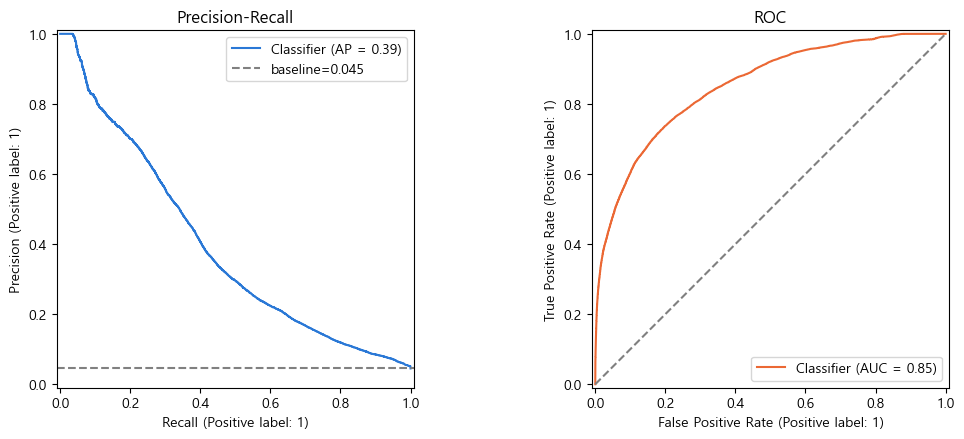

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[0], curve_kwargs={"color": COLOR_PR})
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label=f"baseline={y_test.mean():.3f}")
axes[0].set_title("Precision-Recall")
axes[0].legend()

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], curve_kwargs={"color": COLOR_ROC})
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set_title("ROC")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_pr_roc_curve.png", dpi=150)
plt.show()

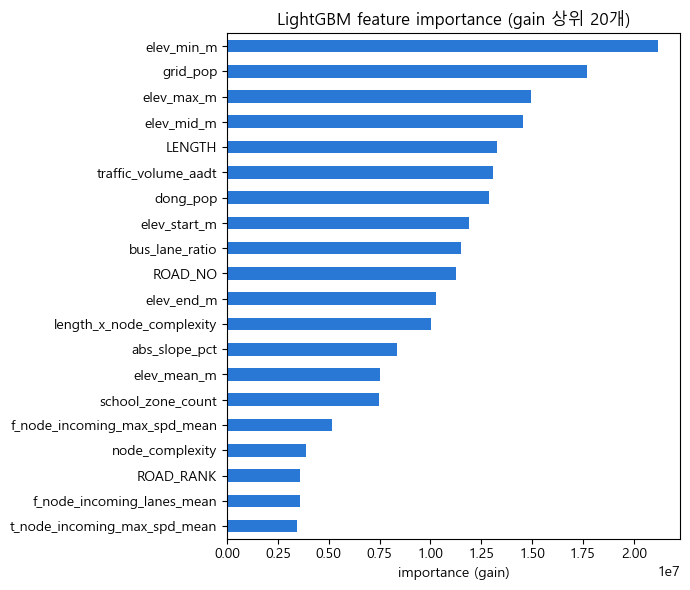

elev_min_m                      2.121491e+07
grid_pop                        1.770756e+07
elev_max_m                      1.496322e+07
elev_mid_m                      1.456780e+07
LENGTH                          1.327217e+07
traffic_volume_aadt             1.309597e+07
dong_pop                        1.285734e+07
elev_start_m                    1.187574e+07
bus_lane_ratio                  1.149995e+07
ROAD_NO                         1.128161e+07
elev_end_m                      1.029420e+07
length_x_node_complexity        1.003096e+07
abs_slope_pct                   8.363050e+06
elev_mean_m                     7.497471e+06
school_zone_count               7.455657e+06
f_node_incoming_max_spd_mean    5.172814e+06
node_complexity                 3.882318e+06
ROAD_RANK                       3.606100e+06
f_node_incoming_lanes_mean      3.573765e+06
t_node_incoming_max_spd_mean    3.421474e+06
dtype: float64

In [13]:
importance = (
    pd.Series(model.feature_importances_, index=feature_cols)
    .sort_values(ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(7, 6))
importance.iloc[::-1].plot.barh(ax=ax, color=COLOR_PR)
ax.set_title("LightGBM feature importance (gain 상위 20개)")
ax.set_xlabel("importance (gain)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_feature_importance.png", dpi=150)
plt.show()

importance

## 다음 단계 (범위 밖)

이번 노트북은 학습/검증까지만 다뤘다. 이후 필요하면:
- SHAP summary/dependence plot으로 상위 피처의 방향성 확인
- `school_zone_count`/`speed_bump_count`처럼 역인과관계 우려가 있는 피처를 제외한 모델과 비교
- 사망자수/중상자수로 가중한 심각도 라벨 버전과 성능 비교
- `N_FOLDS`개 fold 전체 평균으로 안정성 확인(현재는 첫 fold만 사용)